In [60]:
# Import the necessary libraries

import os
import json
import torch
import sklearn
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path
import matplotlib.cm as cm
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch
from category_encoders import BinaryEncoder
from sklearn.metrics import pairwise_distances
from transformers import BertTokenizer, BertModel
from sklearn.metrics import silhouette_score, calinski_harabasz_score, silhouette_samples

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import SpectralClustering
from sklearn.cluster import AffinityPropagation

In [3]:
print(f"Pandas: {pd.__version__}")
print(f"Numpy: {np.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Transformers: {torch.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

Pandas: 2.1.3
Numpy: 1.26.0
Seaborn: 0.12.2
Transformers: 2.1.1+cpu
Scikit-learn: 1.3.2


In [4]:
# A class to load the data from the json files

class DataLoader:
    def __init__(self, data_path):
        self.data_path = data_path

    def load_data(self):
        data_list = []

        for file in os.listdir(self.data_path):
            if file.endswith('.json'):
                data = self._extract_data(os.path.join(self.data_path, file))
                if all(value != '' for value in data.values()):
                    data_list.append(data)

        return pd.DataFrame(data_list)

    def _extract_data(self, file_path):
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)

        protocol = data.get('protocolSection', {})
        identification = protocol.get('identificationModule', {})
        description = protocol.get('descriptionModule', {})
        conditions = protocol.get('conditionsModule', {})
        design = protocol.get('designModule', {})
        eligibility = protocol.get('eligibilityModule', {})

        primary_purpose = design.get('designInfo', {}).get('primaryPurpose', '')


        extracted_data = {
            "NCT ID": self._try_except(identification, 'nctId'),
            "Study Type": self._try_except(design, 'studyType'),
            "Standard Ages": self._try_except(eligibility, 'stdAges', join=True),
            "Conditions": self._try_except(conditions, 'conditions', join=True),
            "Eligibility Criteria": self._try_except(eligibility, 'eligibilityCriteria'),
            "Sex": self._try_except(eligibility, 'sex')
        }

        return extracted_data

    def _try_except(self, data_dict, field_name, join=False):
        try:
            value = data_dict.get(field_name, '')
            if join and isinstance(value, list):
                return ", ".join(value)
            return value
        except Exception as e:
            print(f"Error extracting {field_name}: {str(e)}")
            return ''

In [5]:
def extract_raw_data(input_dir=None, output_file=None):
    '''
    Extracts raw data from the json files and saves it to a csv file.

    Parameters:
    - input_dir (str): The directory containing the input JSON files.
    - output_file (str): The name of the CSV file to save the raw data.

    Returns:
    None
    '''
    if input_dir is None or output_file is None:
        raise ValueError("Both 'input_dir' and 'output_file' must be specified.")

    # Assuming DataLoader is a class that loads data from JSON files
    dataloader = DataLoader(input_dir)
    raw_data = dataloader.load_data()

    # Save raw data to CSV
    raw_data.to_csv(output_file, index=False)

    print(f"Raw data extracted to {output_file}")


In [6]:
input_dir = Path(r'.\data\ctg-studies.json')
output_file = Path(r'.\data\ctg-studies.csv')

extract_raw_data(input_dir=input_dir, output_file=output_file)

Raw data extracted to data\ctg-studies.csv


In [7]:
raw_data = pd.read_csv(r'.\data\ctg-studies.csv')
raw_data.isna().sum()

NCT ID                  0
Study Type              0
Standard Ages           0
Conditions              0
Eligibility Criteria    0
Sex                     0
dtype: int64

In [8]:
raw_data.describe()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
count,1266,1266,1266,1266,1266,1266
unique,1266,3,6,862,1254,3
top,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Multiple Myeloma,"Inclusion Criteria:\n\n1. Age ≥18 years old, m...",ALL
freq,1,1198,836,78,3,1239


In [9]:
raw_data.head()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
0,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Ovarian Cancer,DISEASE CHARACTERISTICS:\n\n* Histologically p...,FEMALE
1,NCT00085930,INTERVENTIONAL,"CHILD, ADULT",Neuroblastoma,Inclusion Criteria:\n\nHigh risk neuroblastoma...,ALL
2,NCT00881920,INTERVENTIONAL,"ADULT, OLDER_ADULT","Lymphoma, Myeloma, Leukemia",INCLUSION CRITERIA:\n\nBLOOD PROCUREMENT:\n\n*...,ALL
3,NCT00902044,INTERVENTIONAL,"CHILD, ADULT, OLDER_ADULT",Sarcoma,INCLUSION CRITERIA:\n\nProcurement Eligibility...,ALL
4,NCT00924326,INTERVENTIONAL,"ADULT, OLDER_ADULT","Primary Mediastinal B-cell Lymphoma, Diffuse, ...",* INCLUSION CRITERIA:\n\n 1. Patient must hav...,ALL


In [10]:
raw_data['Study Type'].value_counts()

Study Type
INTERVENTIONAL     1198
OBSERVATIONAL        63
EXPANDED_ACCESS       5
Name: count, dtype: int64

In [11]:
raw_data['Standard Ages'].value_counts()

Standard Ages
ADULT, OLDER_ADULT           836
CHILD, ADULT, OLDER_ADULT    316
CHILD, ADULT                  97
ADULT                          9
CHILD                          7
OLDER_ADULT                    1
Name: count, dtype: int64

In [12]:
raw_data['Sex'].value_counts()

Sex
ALL       1239
FEMALE      15
MALE        12
Name: count, dtype: int64

In [13]:
def extract_features(data=None, bert_model=None, tokenizer=None, encoder=BinaryEncoder,col='NCT ID'):
    '''
    Extracts features from the eligibility criteria using the BERT model.

    Parameters:
    - data (pd.DataFrame): The data containing the eligibility criteria.
    - bert_model (str): The name of the BERT model to use.
    - tokenizer (str): The name of the tokenizer to use.

    Returns:
    pd.DataFrame: The data with the extracted features.
    '''
    if data is None or bert_model is None or tokenizer is None:
        raise ValueError("All parameters must be specified.")

    # Load the BERT model and tokenizer
    bert_model = BertModel.from_pretrained(bert_model)
    tokenizer = BertTokenizer.from_pretrained(tokenizer)

    # Extract features from the eligibility criteria
    features = []
    for text in tqdm(data[col]):
        inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        outputs = bert_model(**inputs)
        features.append(outputs.pooler_output.detach().numpy())

    features = [feature.flatten() for feature in features]
    # Add the extracted features to the data
    features = pd.DataFrame(features)
    if col == 'NCT ID':
        features.columns = [f"feature_{i}" for i in range(features.shape[1])]
    else:
        features.columns = [f"feature_{i+1024}" for i in range(features.shape[1])] 

    return features

# Datasets

In [14]:
feature_matrix_biobert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_biobert.csv')
feature_matrix_bluebert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_bluebert.csv')
feature_matrix_biomedbert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_biomedbert.csv')

In [15]:
# Function to plot silhouette plots
# Inspired from scikit learn
# https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html

def plot_silhouette_samples(X, labels):
    silhouette_avg = silhouette_score(X, labels)
    print("The average silhouette_score is :", silhouette_avg)

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, labels)

    plt.figure(figsize=(8, 6))
    y_lower = 10

    for i in np.unique(labels):
        ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / len(np.unique(labels)))
        plt.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for the next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    plt.title("Silhouette plot for the various clusters")
    plt.xlabel("The silhouette coefficient values")
    plt.ylabel("Cluster label")

    # The vertical line for the average silhouette score of all the values
    plt.axvline(x=silhouette_avg, color="red", linestyle="--")

    plt.yticks([])  # Clear the y-axis labels / ticks
    plt.xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    plt.show()

# KMeans

## Bluebert

In [16]:
# Dataset Bluebert
X_bluebert = feature_matrix_bluebert.drop(columns=['NCT ID'])

# PCA
pca_bluebert = PCA(n_components=256)
X_pca_bluebert = pca_bluebert.fit_transform(X_bluebert)
print(f"Explained variance ratio - Bluebert: {sum(pca_bluebert.explained_variance_ratio_)}")

Explained variance ratio - Bluebert: 0.998923833172027


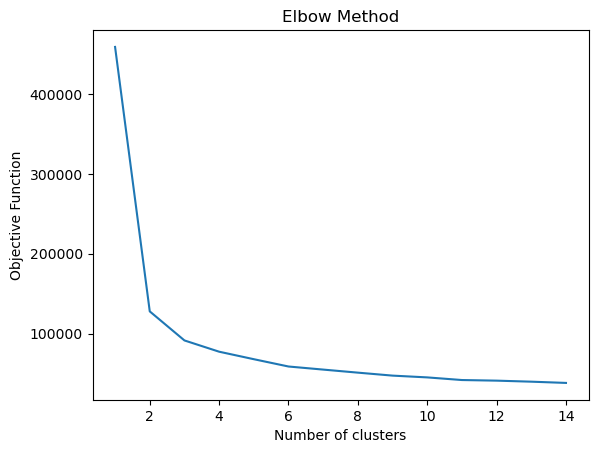

In [17]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_bluebert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 2
So the optimal number of clusters is 2

The average silhouette_score is : 0.6625638491181184


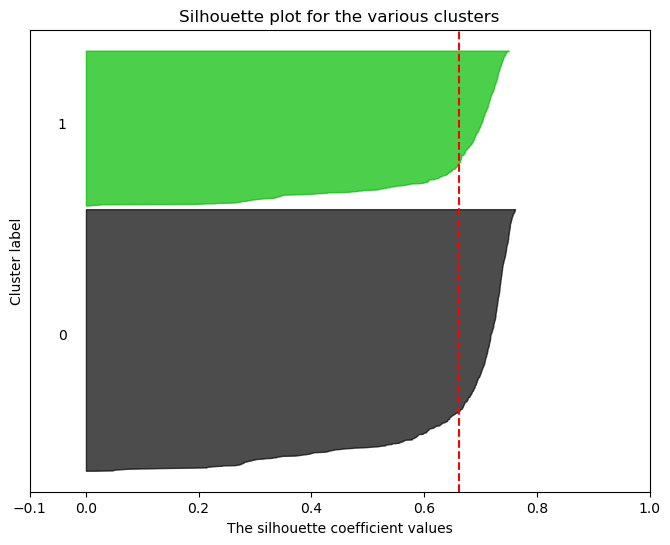

In [18]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_bluebert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_bluebert, labels)

## Biomedbert

In [19]:
# Dataset Biomedbert
X_biomedbert = feature_matrix_biomedbert.drop(columns=['NCT ID'])

# PCA
pca_biomedbert = PCA(n_components=1024)
X_pca_biomedbert = pca_biomedbert.fit_transform(X_biomedbert)
print(f"Explained variance ratio - Biomedbert: {sum(pca_biomedbert.explained_variance_ratio_)}")

Explained variance ratio - Biomedbert: 0.9998763227130608


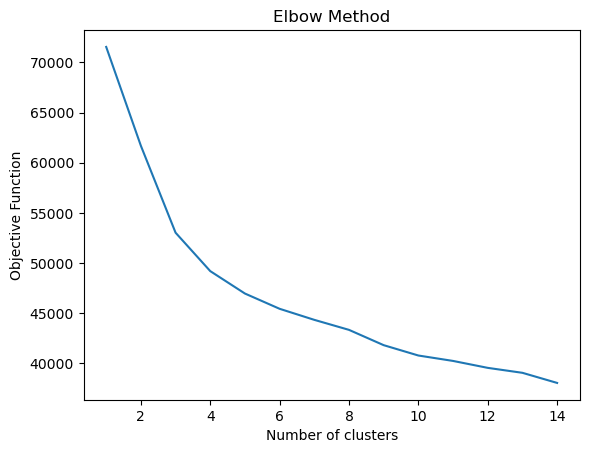

In [20]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_biomedbert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 3
So the optimal number of clusters is 3

The average silhouette_score is : 0.1790932843063201


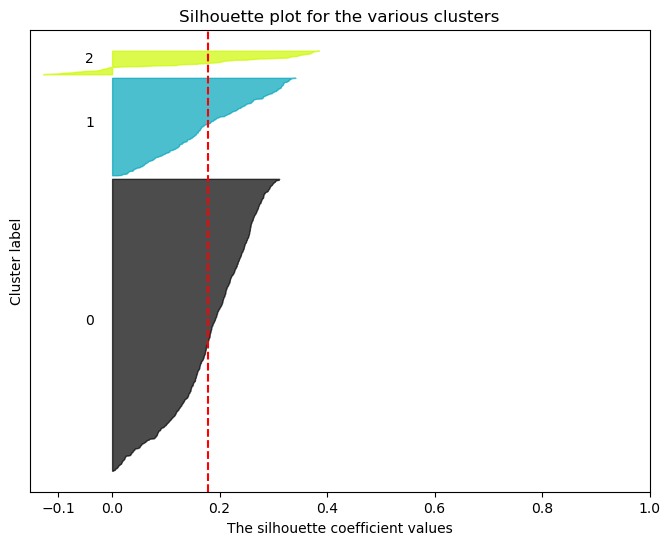

In [21]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_biomedbert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_biomedbert, labels)

## Biobert

In [22]:
# Dataset biobert
X_biobert = feature_matrix_biobert.drop(columns=['NCT ID'])

# PCA
pca_biobert = PCA(n_components=256)
X_pca_biobert = pca_biobert.fit_transform(X_biobert)
print(f"Explained variance ratio - Biobert: {sum(pca_biobert.explained_variance_ratio_)}")

Explained variance ratio - Biobert: 0.9972789203258774


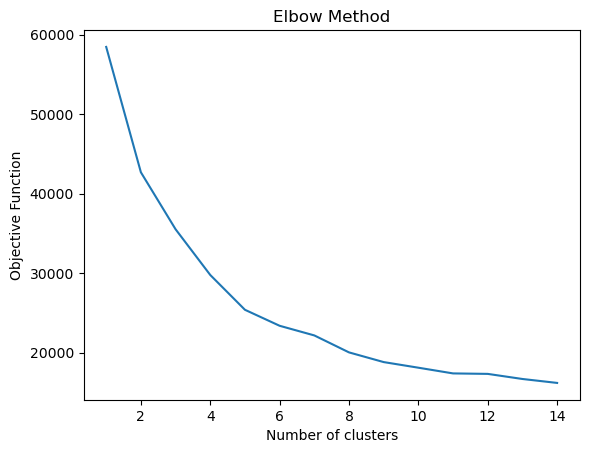

In [23]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_biobert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 3
So the optimal number of clusters is 3

The average silhouette_score is : 0.1790932843063201


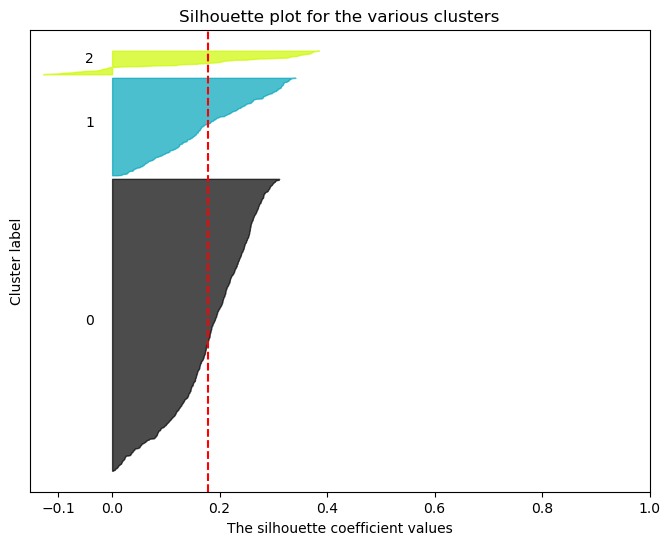

In [24]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_biomedbert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_biomedbert, labels)

# Agglomerative Clustering

## Bluebert

Optimal number of clusters: 2


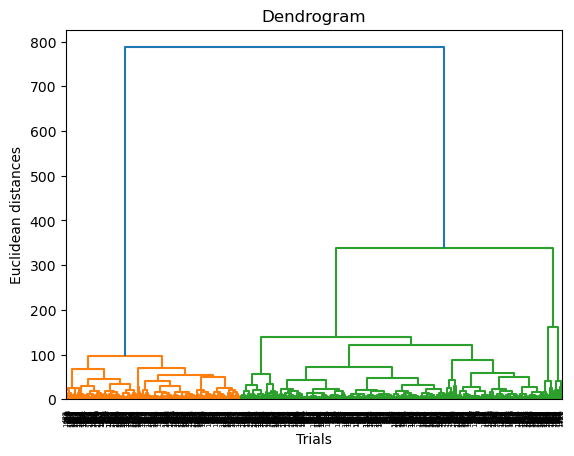

In [52]:
# Dendogram
import scipy.cluster.hierarchy as sch
cluster_visualising=sch.dendrogram(sch.linkage(X_pca_bluebert,method='ward', metric='euclidean'))

unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")
plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.6456584463655285


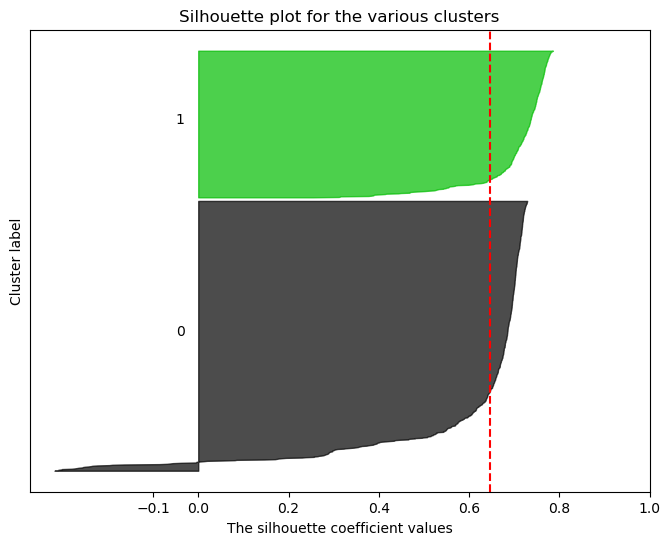

[0 1 0 ... 1 0 1]


In [94]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_bluebert)

plot_silhouette_samples(X_pca_bluebert, labels)
print(labels)

## Biobert

Optimal number of clusters: 7


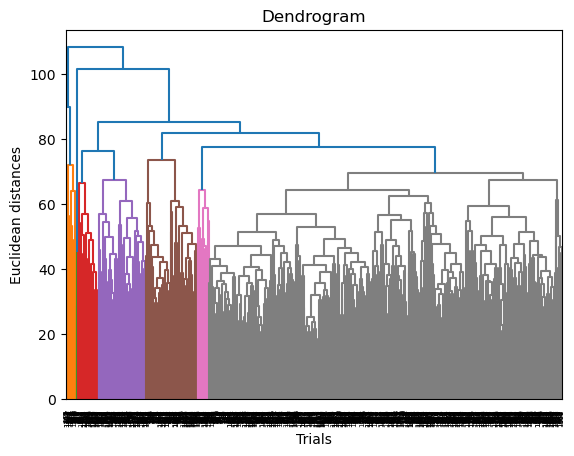

In [57]:
# Dendogram

cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biobert,method='complete', metric='cityblock'))

unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")
plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.25007052775686944


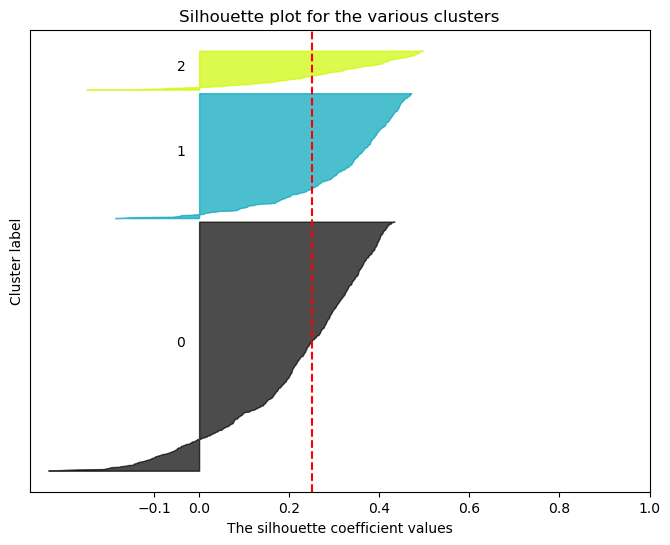

In [28]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_biobert)

plot_silhouette_samples(X_pca_biobert, labels)

## Biomedbert

Optimal number of clusters: 3


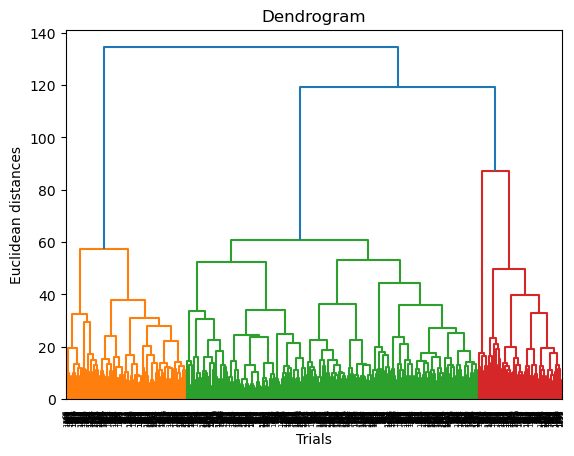

In [29]:
# Dendogram
import scipy.cluster.hierarchy as sch
cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biomedbert,method='ward'))
unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")

plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.1363516627472447


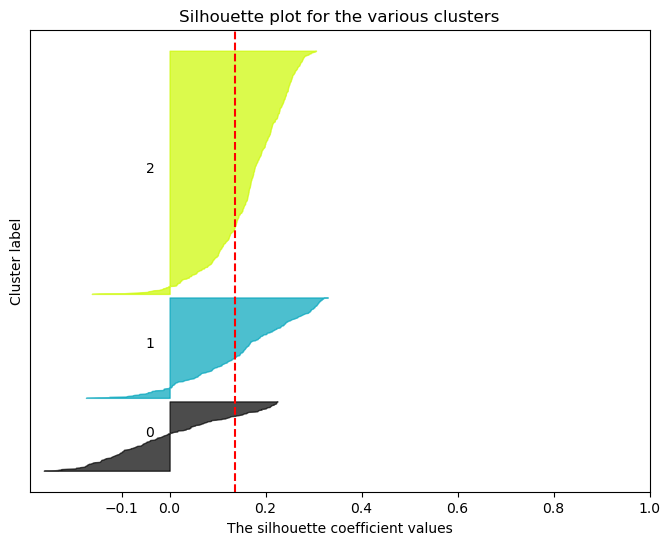

In [65]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_biomedbert)

plot_silhouette_samples(X_pca_biomedbert, labels)

In [67]:
def plot_dendograms(dataset=None):
    linkages = ['single', 'complete', 'average']
    metrics = ['euclidean', 'cityblock', 'cosine']

    for linkage in linkages:
        print(f"Linkage: {linkage}")
        for metric in metrics:
            print(f"Metric: {metric}")
            cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biobert,method=linkage, metric=metric))
            unique_colors = np.unique(cluster_visualising['color_list'])
            print(f"Optimal number of clusters: {len(unique_colors)-1}")
            plt.title('Dendrogram')
            plt.xlabel('Trials')
            plt.ylabel('Euclidean distances')
            plt.show()
        print()

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


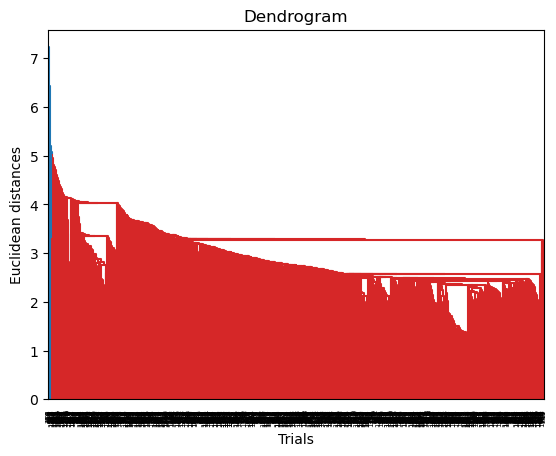

Metric: cityblock
Optimal number of clusters: 5


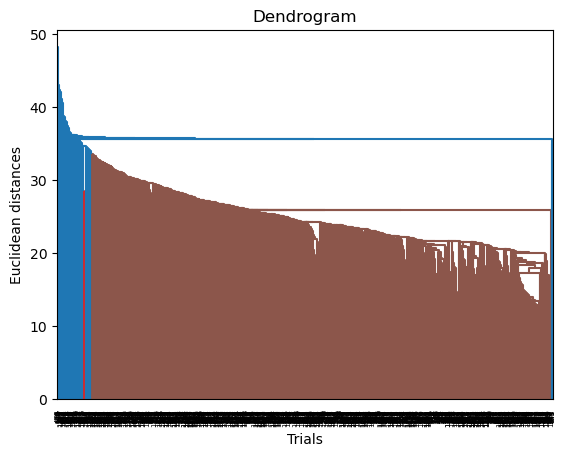

Metric: cosine
Optimal number of clusters: 4


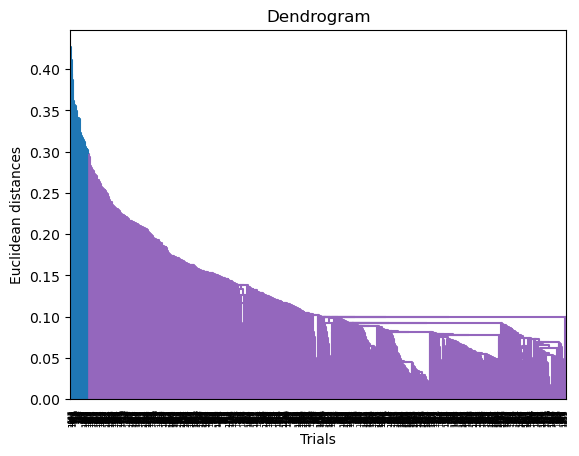


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


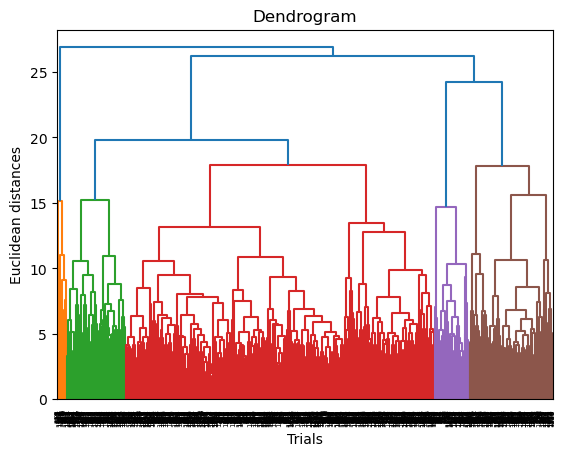

Metric: cityblock
Optimal number of clusters: 7


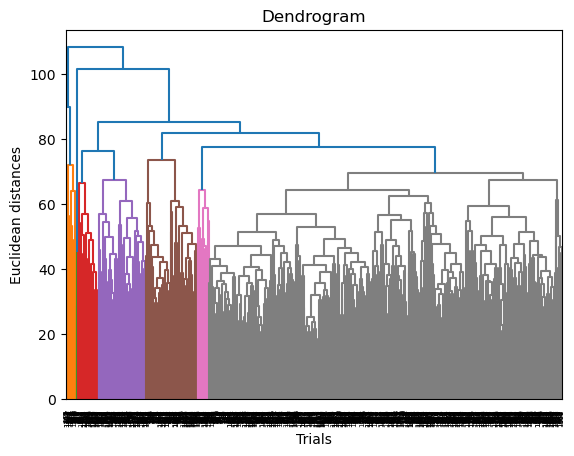

Metric: cosine
Optimal number of clusters: 9


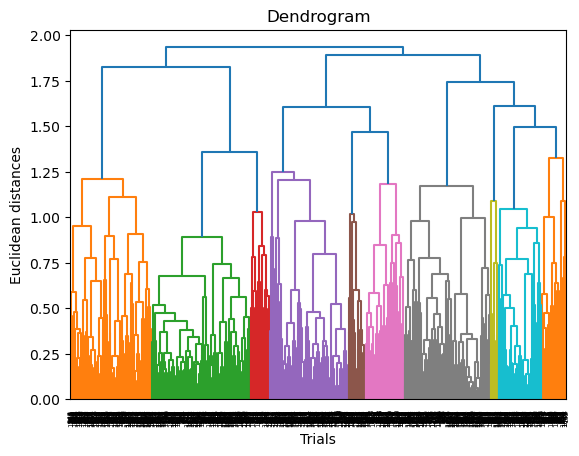


Linkage: average
Metric: euclidean
Optimal number of clusters: 7


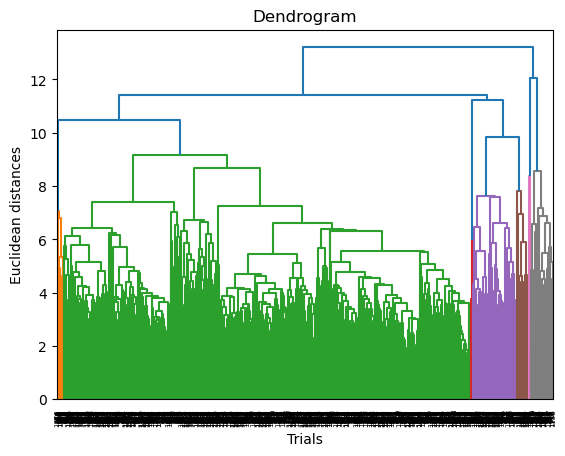

Metric: cityblock
Optimal number of clusters: 3


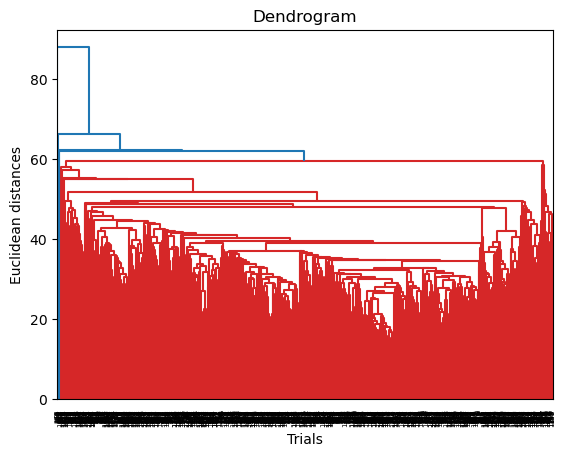

Metric: cosine
Optimal number of clusters: 5


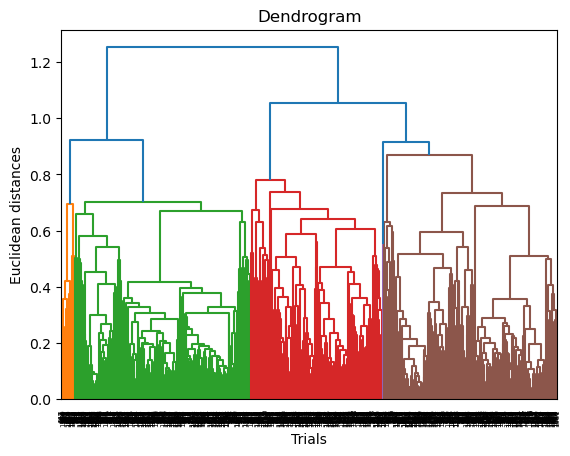

In [68]:
plot_dendograms(X_pca_biobert)

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


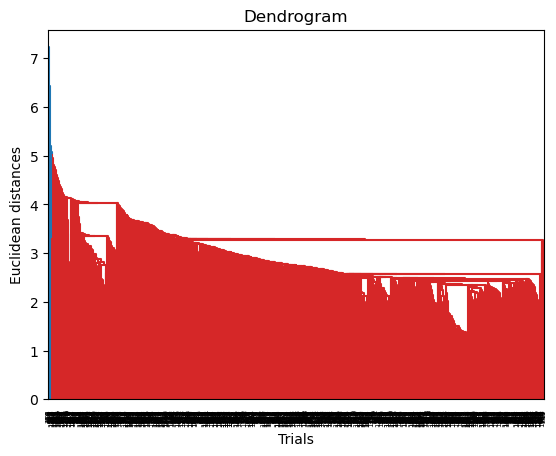

Metric: cityblock
Optimal number of clusters: 5


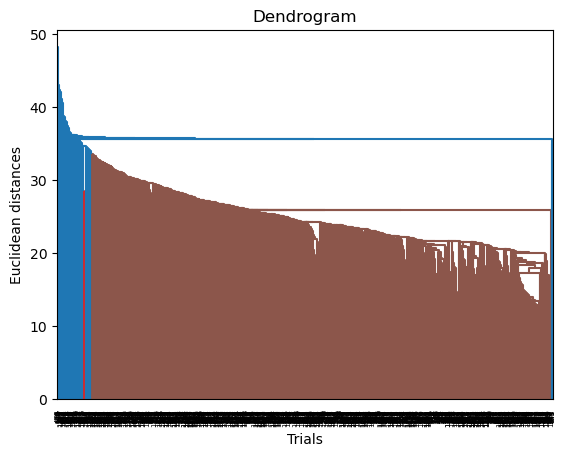

Metric: cosine
Optimal number of clusters: 4


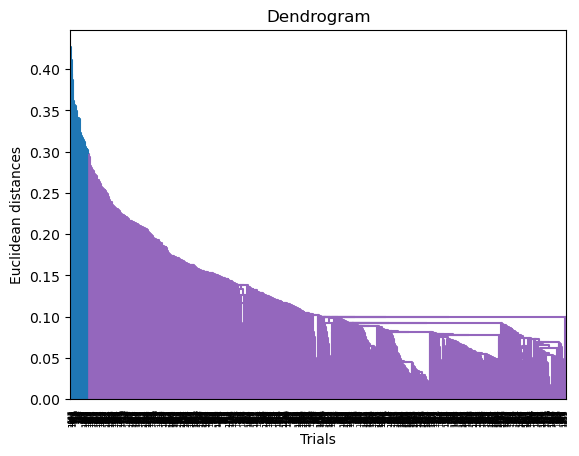


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


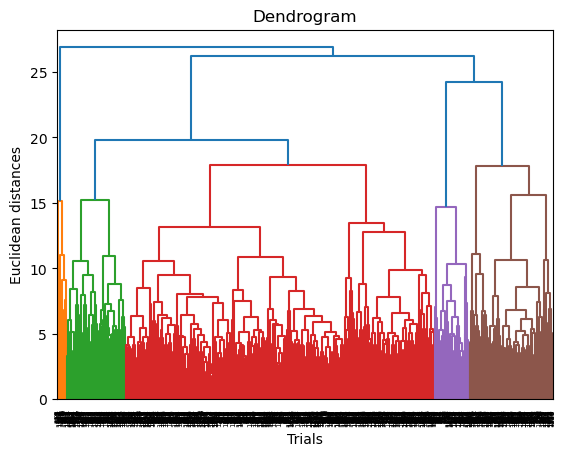

Metric: cityblock
Optimal number of clusters: 7


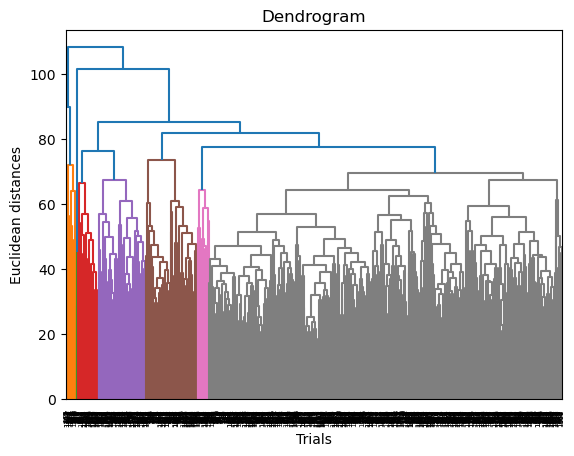

Metric: cosine
Optimal number of clusters: 9


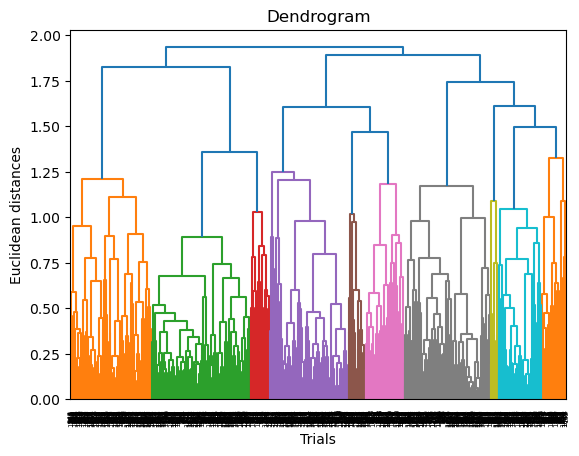


Linkage: average
Metric: euclidean
Optimal number of clusters: 7


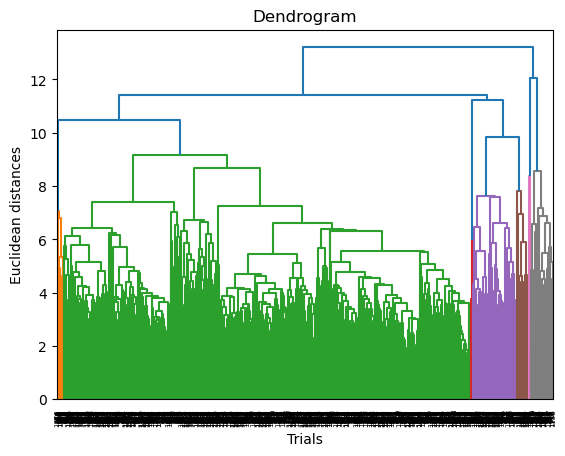

Metric: cityblock
Optimal number of clusters: 3


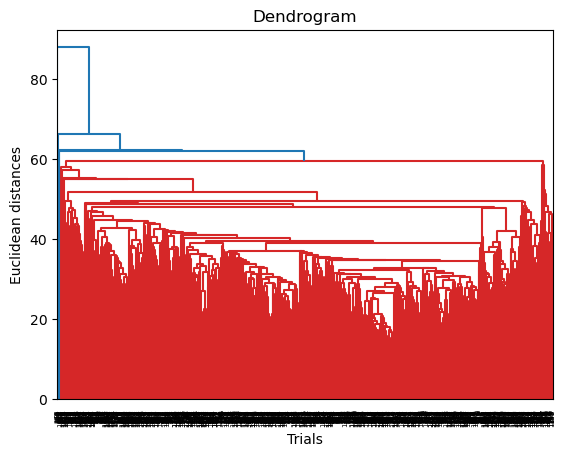

Metric: cosine
Optimal number of clusters: 5


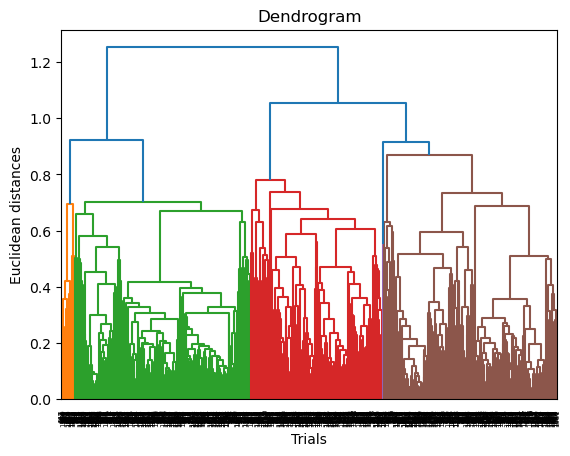

In [69]:
plot_dendograms(X_pca_bluebert)

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


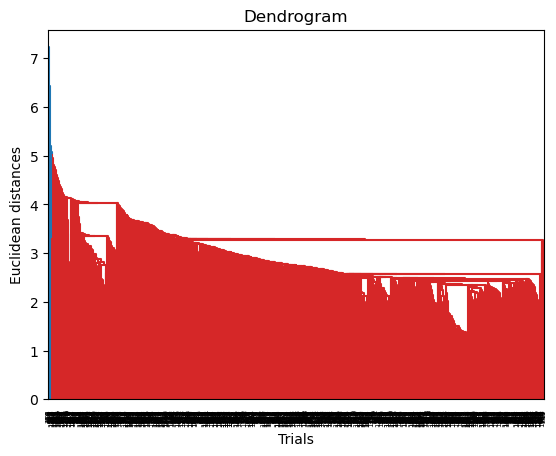

Metric: cityblock
Optimal number of clusters: 5


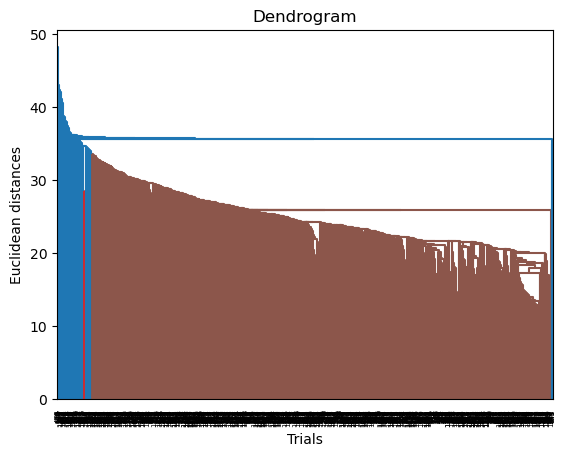

Metric: cosine
Optimal number of clusters: 4


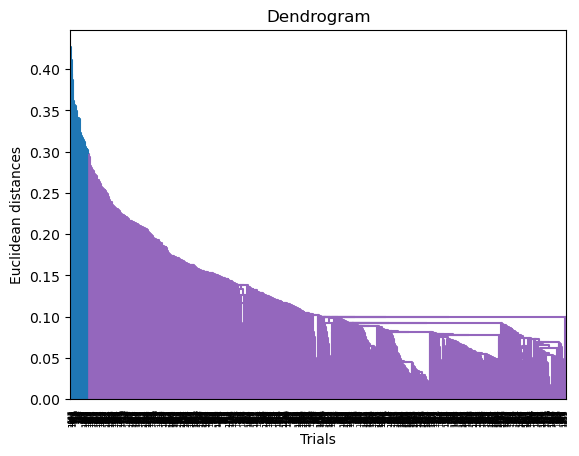


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


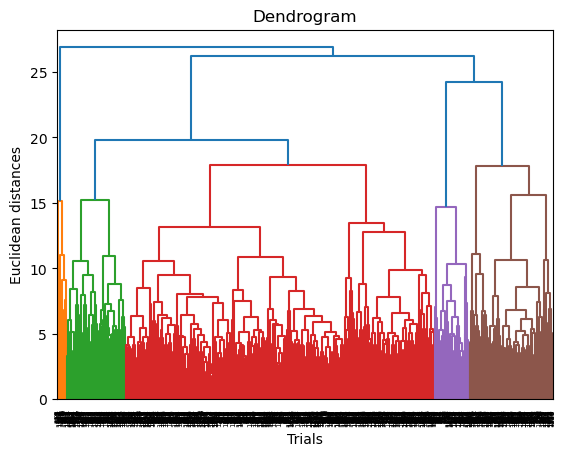

Metric: cityblock
Optimal number of clusters: 7


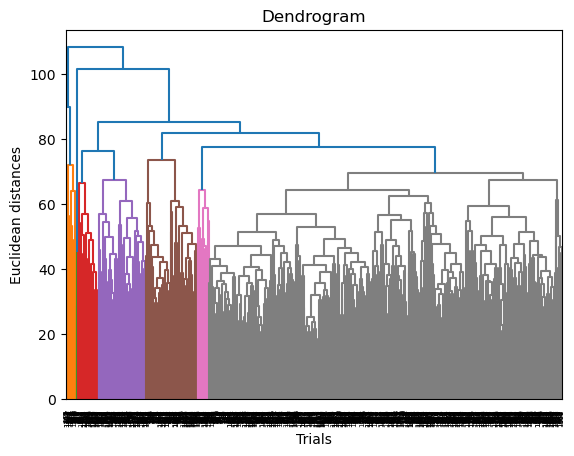

Metric: cosine
Optimal number of clusters: 9


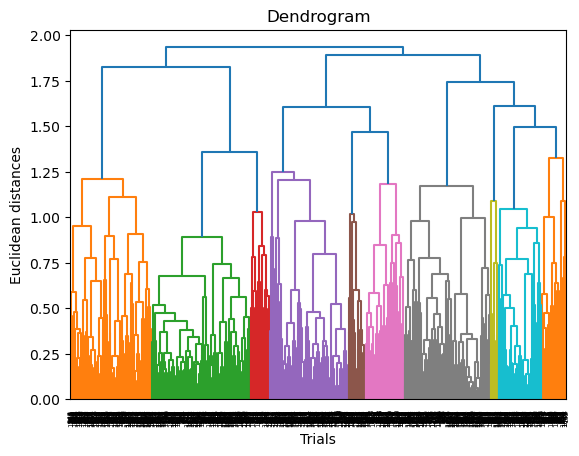


Linkage: average
Metric: euclidean
Optimal number of clusters: 7


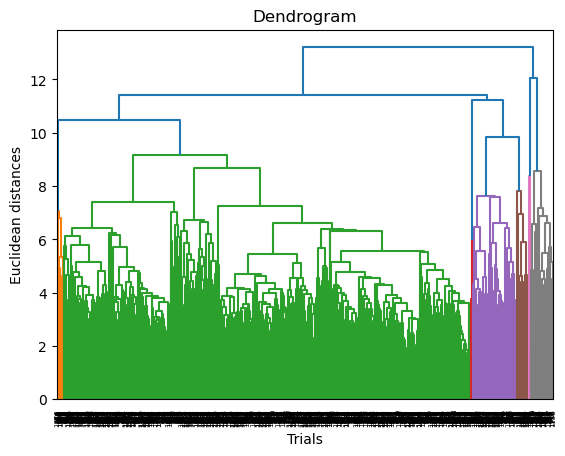

Metric: cityblock
Optimal number of clusters: 3


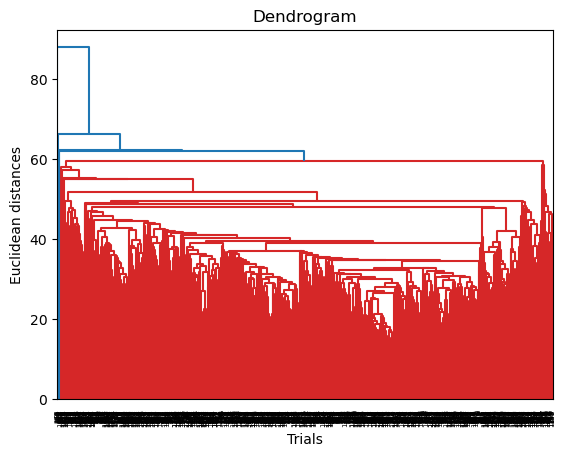

Metric: cosine
Optimal number of clusters: 5


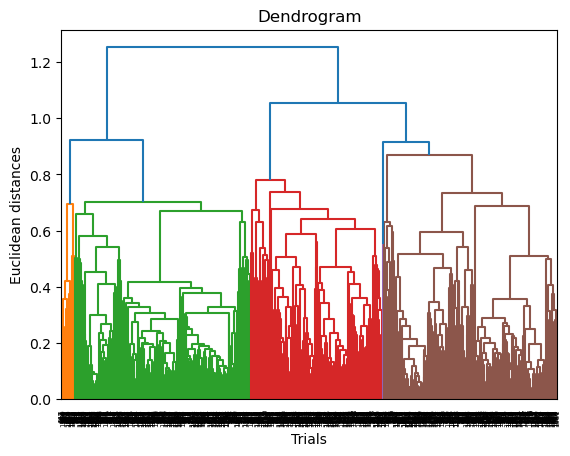

In [70]:
plot_dendograms(X_pca_bluebert)

# Spectral Clustering

In [31]:
def getAffinityMatrix(coordinates, k=7):
    """
    Calculate affinity matrix based on input  matrix and the number
    of nearest neighbours.
    
    Apply local scaling based on the k nearest neighbour
    References:
    https://papers.nips.cc/paper/2619-self-tuning-spectral-clustering.pdf
    """
    # calculate euclidean distance matrix using pairwise_distances
    dists = pairwise_distances(coordinates, metric='euclidean')
    
    # for each row, sort the distances ascendingly and take the index of the 
    # k-th position (nearest neighbour)
    knn_distances = np.sort(dists, axis=0)[k]
    knn_distances = knn_distances[np.newaxis].T
    
    # calculate sigma_i * sigma_j
    local_scale = knn_distances.dot(knn_distances.T)

    affinity_matrix = dists * dists
    affinity_matrix = -affinity_matrix / local_scale
    # divide square distance matrix by local scale
    affinity_matrix[np.where(np.isnan(affinity_matrix))] = 0.0
    # apply exponential
    affinity_matrix = np.exp(affinity_matrix)
    np.fill_diagonal(affinity_matrix, 0)
    return affinity_matrix


In [32]:
import scipy
from scipy.sparse import csgraph
# from scipy.sparse.linalg import eigsh
from numpy import linalg as LA
def eigenDecomposition(A, plot = True, topK = 5):
    """
    :param A: Affinity matrix
    :param plot: plots the sorted eigen values for visual inspection
    :return A tuple containing:
    - the optimal number of clusters by eigengap heuristic
    - all eigen values
    - all eigen vectors
    
    This method performs the eigen decomposition on a given affinity matrix,
    following the steps recommended in the paper:
    1. Construct the normalized affinity matrix: L = D-1/2AD^ -1/2.
    2. Find the eigenvalues and their associated eigen vectors
    3. Identify the maximum gap which corresponds to the number of clusters
    by eigengap heuristic
    
    References:
    https://papers.nips.cc/paper/2619-self-tuning-spectral-clustering.pdf
    http://www.kyb.mpg.de/fileadmin/user_upload/files/publications/attachments/Luxburg07_tutorial_4488%5b0%5d.pdf
    """
    L = csgraph.laplacian(A, normed=True)
    n_components = A.shape[0]
    
    # LM parameter : Eigenvalues with largest magnitude (eigs, eigsh), that is, largest eigenvalues in 
    # the euclidean norm of complex numbers.
#     eigenvalues, eigenvectors = eigsh(L, k=n_components, which="LM", sigma=1.0, maxiter=5000)
    eigenvalues, eigenvectors = LA.eig(L)
    
    if plot:
        plt.title('Largest eigen values of input matrix')
        plt.scatter(np.arange(len(eigenvalues)), eigenvalues)
        plt.grid()
        
    # Identify the optimal number of clusters as the index corresponding
    # to the larger gap between eigen values
    index_largest_gap = np.argsort(np.diff(eigenvalues))[::-1][:topK]
    nb_clusters = index_largest_gap + 1
        
    return nb_clusters, eigenvalues, eigenvectors

Optimal number of clusters: [2 3 5 4 9]


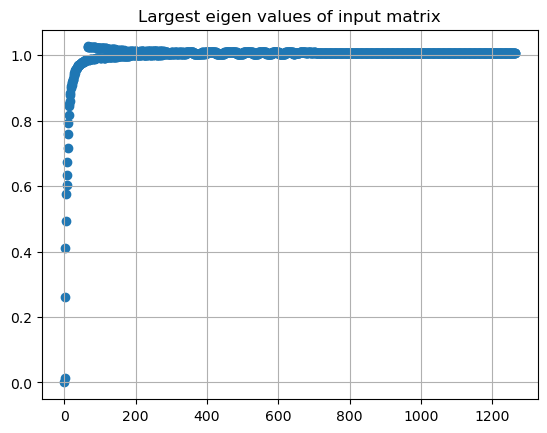

In [33]:
affinity_matrix = getAffinityMatrix(X_pca_bluebert, k=100)
k, _, _ = eigenDecomposition(affinity_matrix, plot=True, topK=5)
print(f"Optimal number of clusters: {k}")

## Bluebert

# DBSCAN

eps value is 6.3 min_samples is 11
{0, 1, 2, -1}
For eps value = 6.3 The average silhouette_score is :0.6047312893455468
The average silhouette_score is : 0.6047312893455468


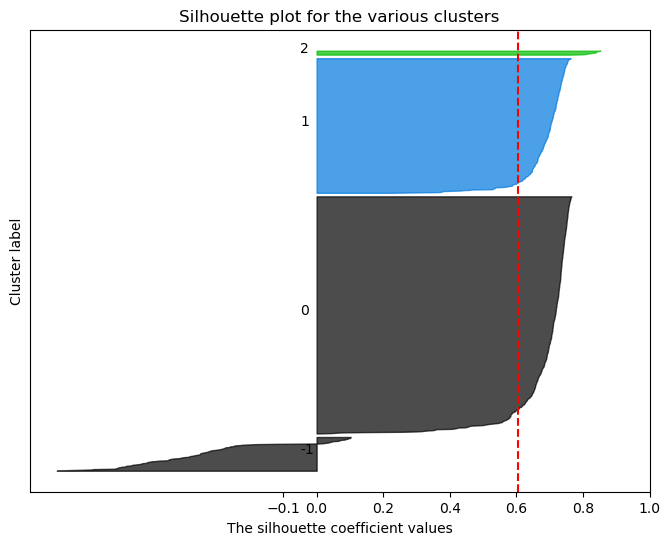

eps value is 6.3 min_samples is 12
{0, 1, 2, -1}
For eps value = 6.3 The average silhouette_score is :0.5992724481301192
The average silhouette_score is : 0.5992724481301192


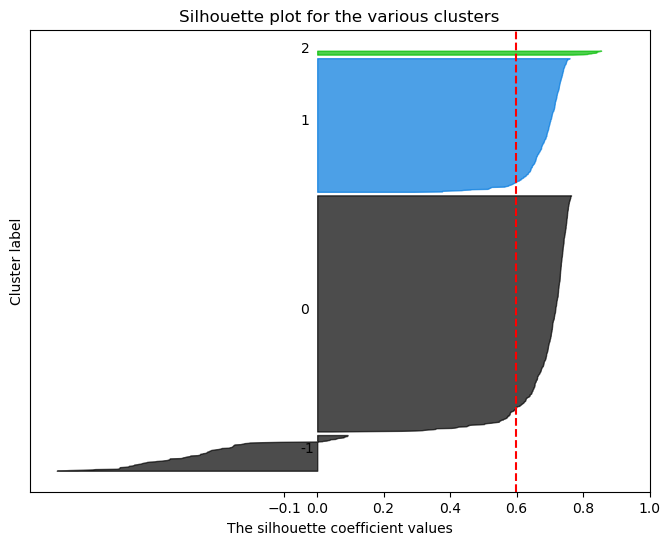

eps value is 6.3 min_samples is 13
{0, 1, 2, -1}
For eps value = 6.3 The average silhouette_score is :0.5992724481301192
The average silhouette_score is : 0.5992724481301192


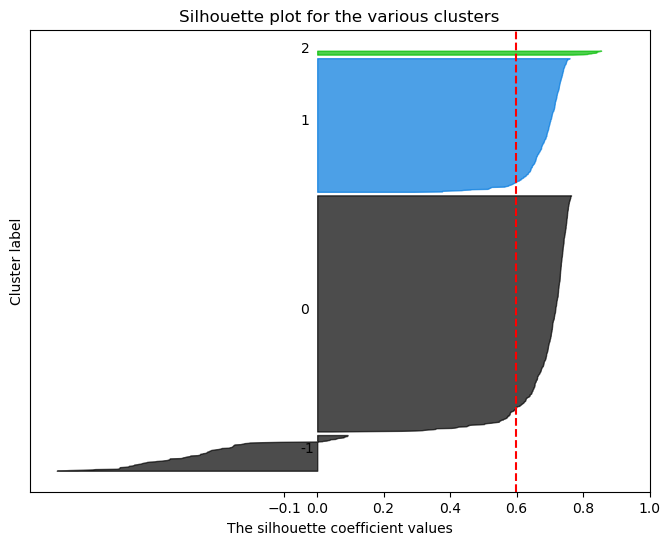

eps value is 6.3 min_samples is 14
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.6085257266862731
The average silhouette_score is : 0.6085257266862731


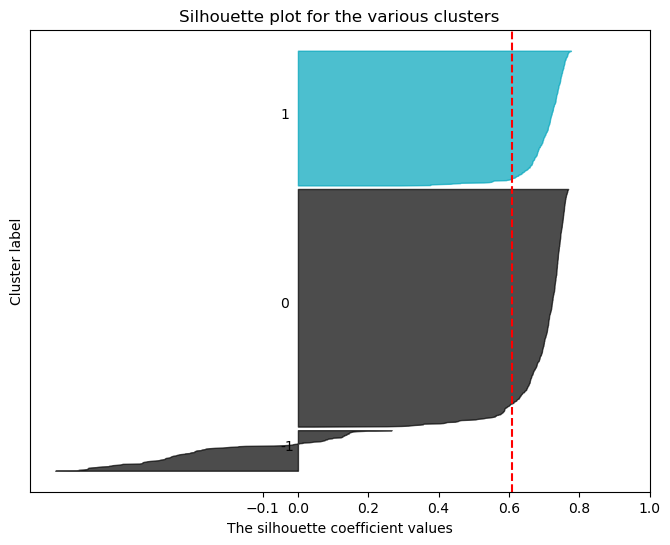

eps value is 6.3 min_samples is 15
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.6005916618440459
The average silhouette_score is : 0.6005916618440459


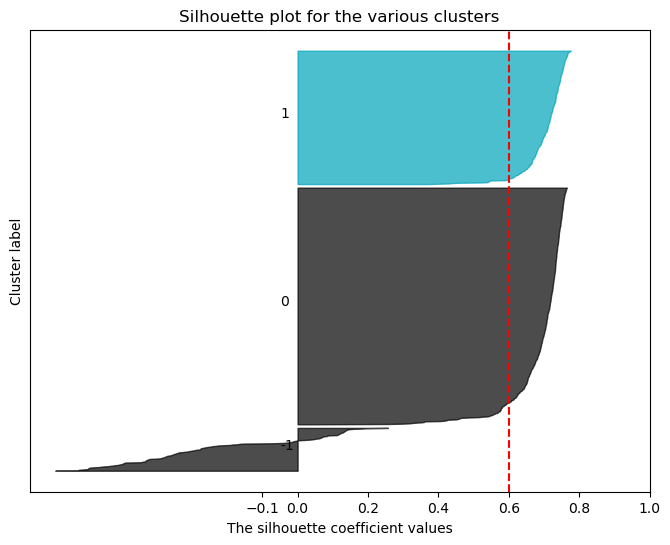

eps value is 6.3 min_samples is 16
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.5936162462746896
The average silhouette_score is : 0.5936162462746896


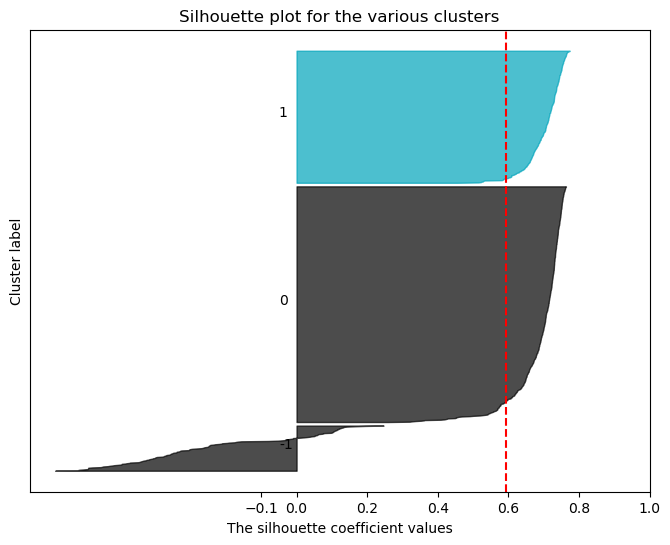

eps value is 6.3 min_samples is 17
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.5901981657657779
The average silhouette_score is : 0.5901981657657779


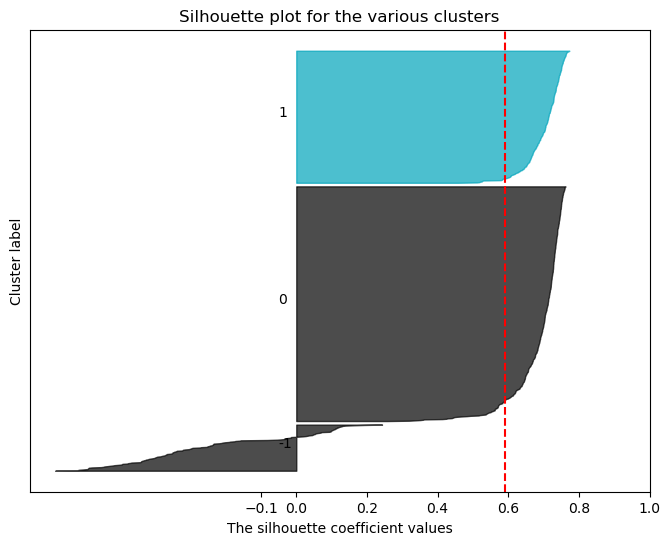

eps value is 6.3 min_samples is 18
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.5881603553114674
The average silhouette_score is : 0.5881603553114674


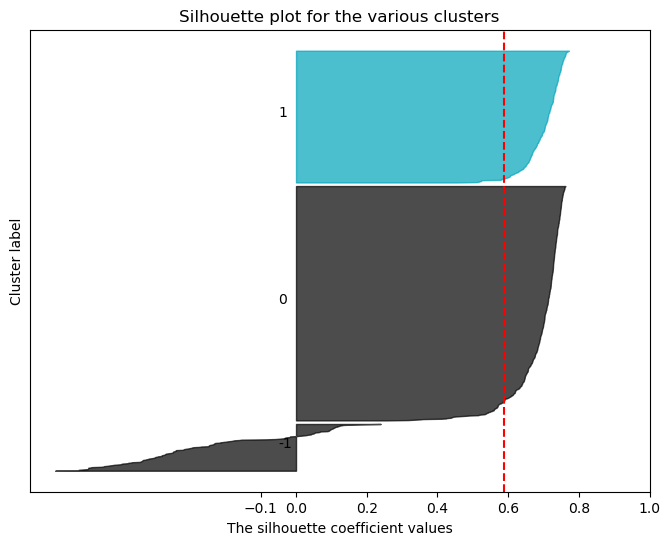

eps value is 6.3 min_samples is 19
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.5817478754192444
The average silhouette_score is : 0.5817478754192444


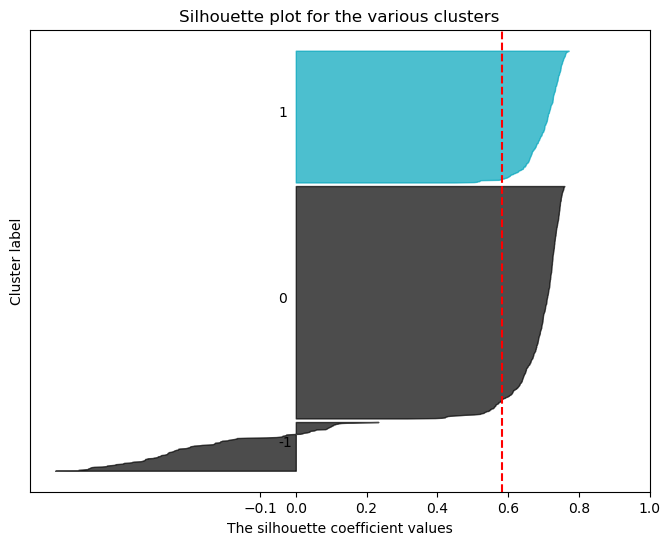

eps value is 6.3 min_samples is 20
{0, 1, -1}
For eps value = 6.3 The average silhouette_score is :0.5817478754192444
The average silhouette_score is : 0.5817478754192444


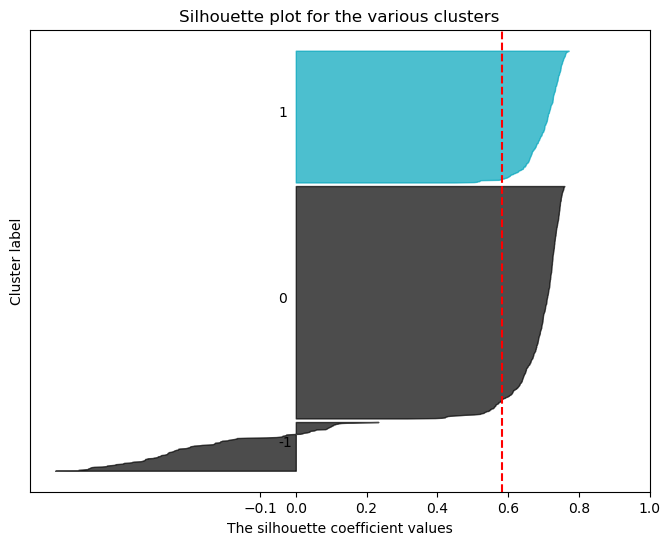

eps value is 6.5 min_samples is 11
{0, 1, 2, -1}
For eps value = 6.5 The average silhouette_score is :0.6156367691833452
The average silhouette_score is : 0.6156367691833452


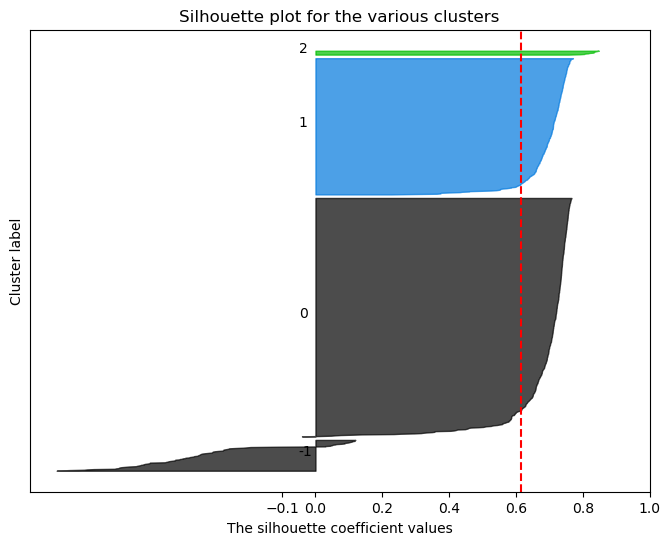

eps value is 6.5 min_samples is 12
{0, 1, 2, -1}
For eps value = 6.5 The average silhouette_score is :0.6130675999693278
The average silhouette_score is : 0.6130675999693278


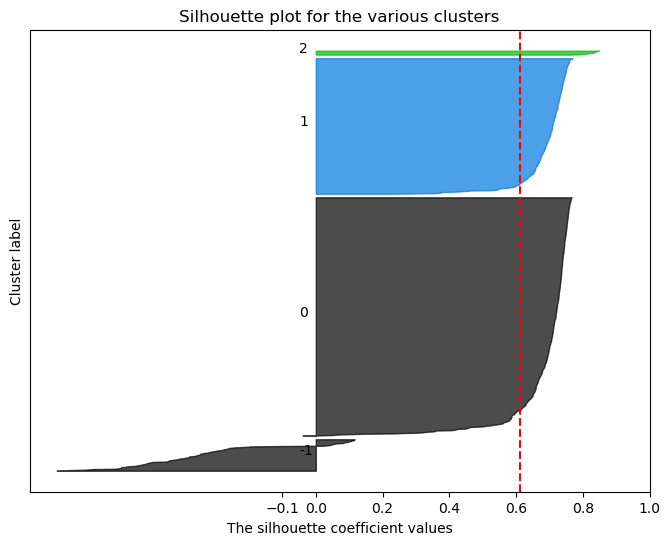

eps value is 6.5 min_samples is 13
{0, 1, 2, -1}
For eps value = 6.5 The average silhouette_score is :0.6119327086663887
The average silhouette_score is : 0.6119327086663887


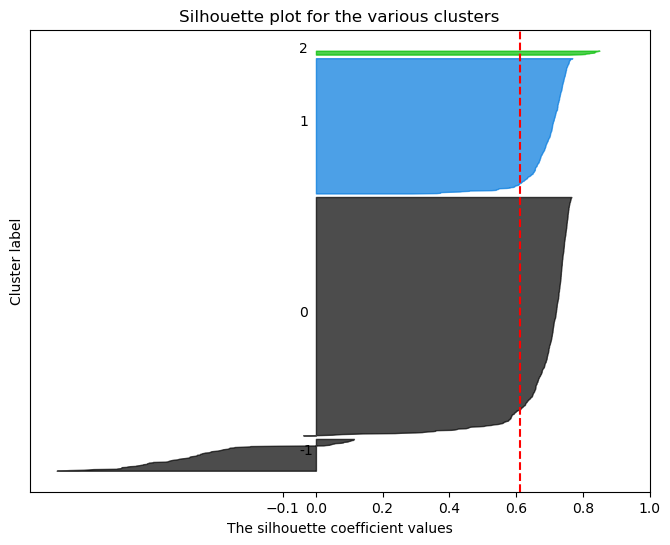

eps value is 6.5 min_samples is 14
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.6222261042338753
The average silhouette_score is : 0.6222261042338753


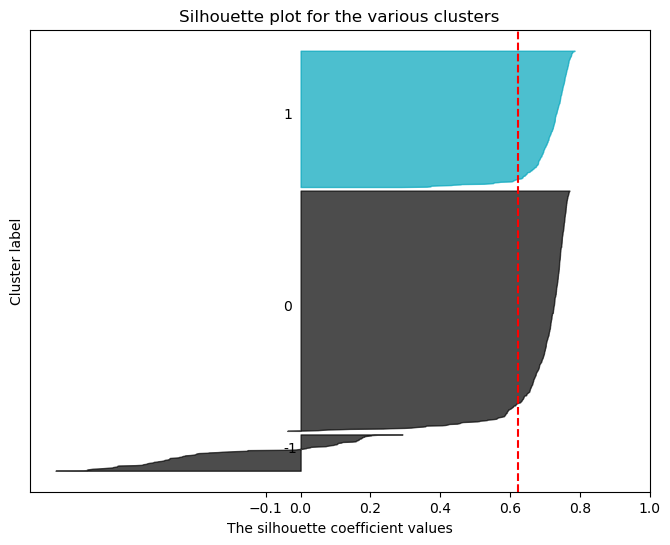

eps value is 6.5 min_samples is 15
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.617796173585581
The average silhouette_score is : 0.617796173585581


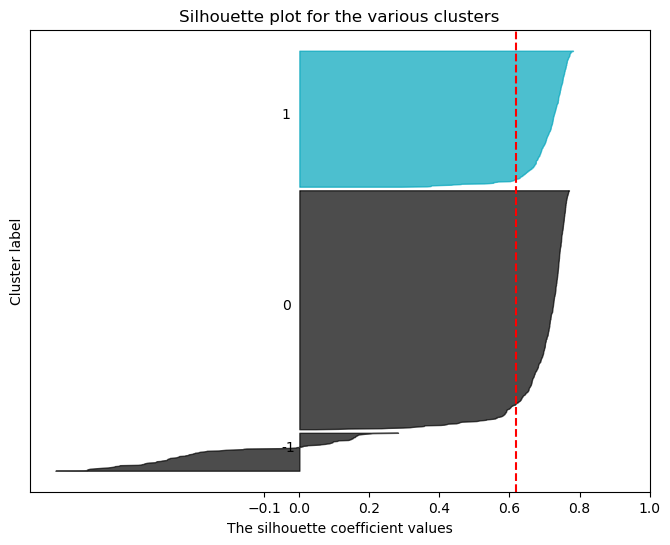

eps value is 6.5 min_samples is 16
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.612021291058725
The average silhouette_score is : 0.612021291058725


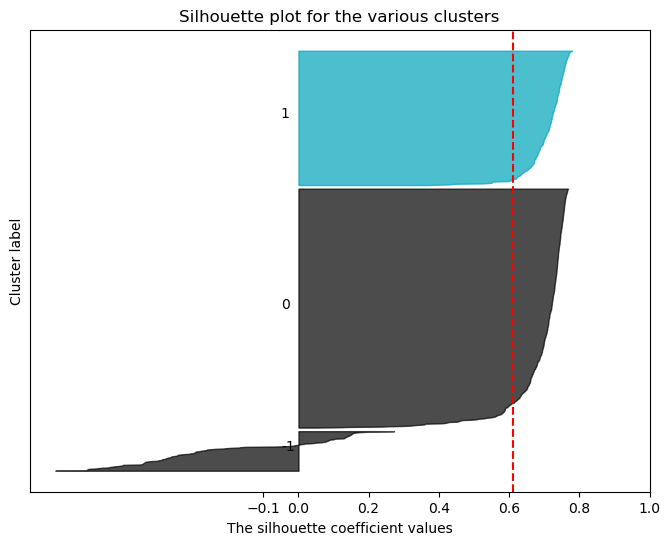

eps value is 6.5 min_samples is 17
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.6052923774600207
The average silhouette_score is : 0.6052923774600207


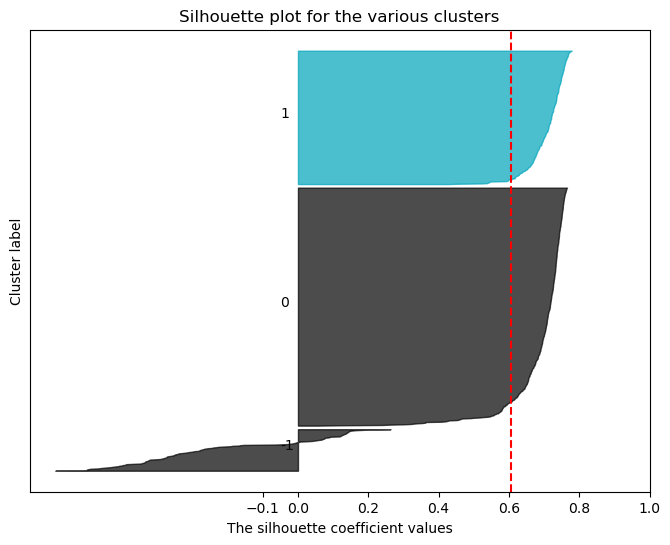

eps value is 6.5 min_samples is 18
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.6031456805693401
The average silhouette_score is : 0.6031456805693401


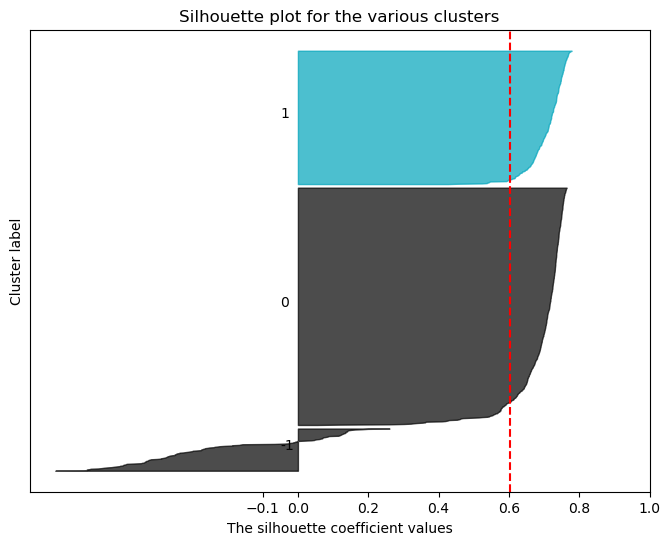

eps value is 6.5 min_samples is 19
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.6019986325358595
The average silhouette_score is : 0.6019986325358595


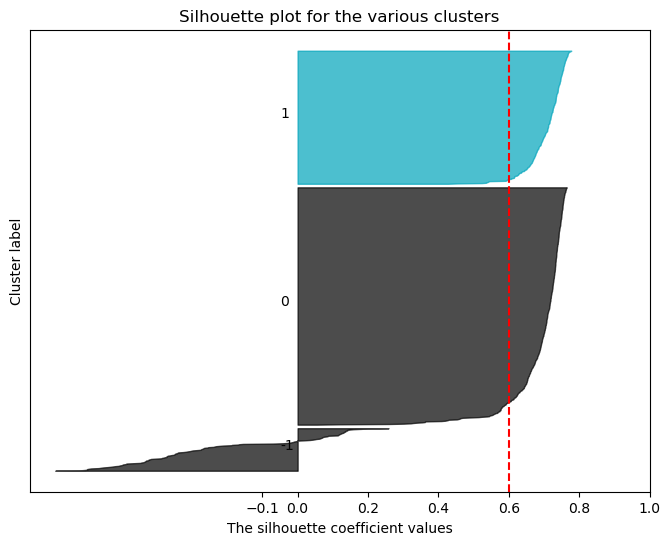

eps value is 6.5 min_samples is 20
{0, 1, -1}
For eps value = 6.5 The average silhouette_score is :0.6019986325358595
The average silhouette_score is : 0.6019986325358595


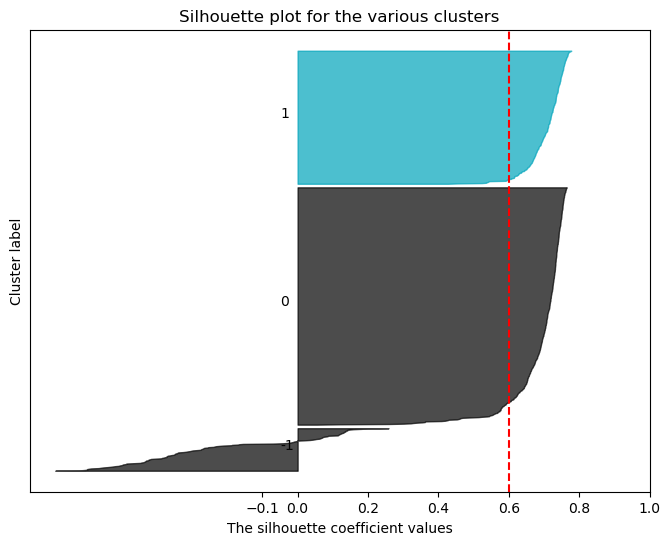

eps value is 6.7 min_samples is 11
{0, 1, 2, -1}
For eps value = 6.7 The average silhouette_score is :0.6276726515180318
The average silhouette_score is : 0.6276726515180318


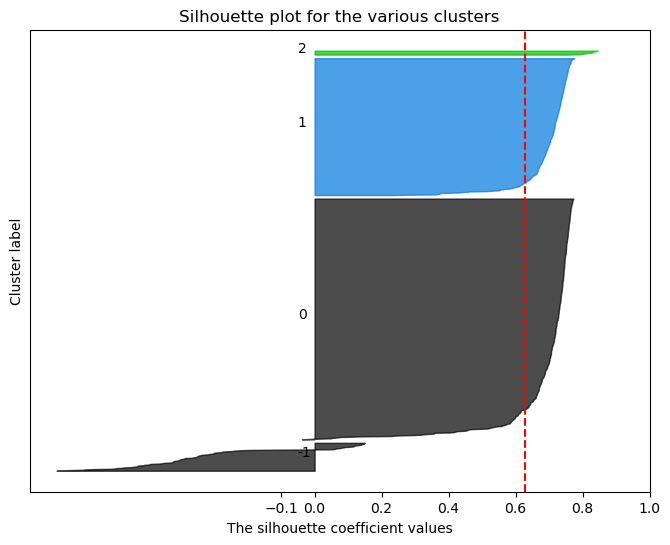

eps value is 6.7 min_samples is 12
{0, 1, 2, -1}
For eps value = 6.7 The average silhouette_score is :0.624426595241268
The average silhouette_score is : 0.624426595241268


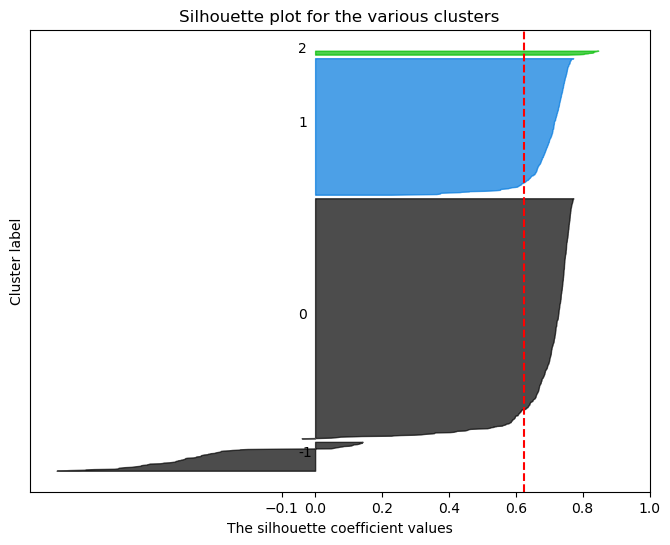

eps value is 6.7 min_samples is 13
{0, 1, 2, -1}
For eps value = 6.7 The average silhouette_score is :0.6202535260818134
The average silhouette_score is : 0.6202535260818134


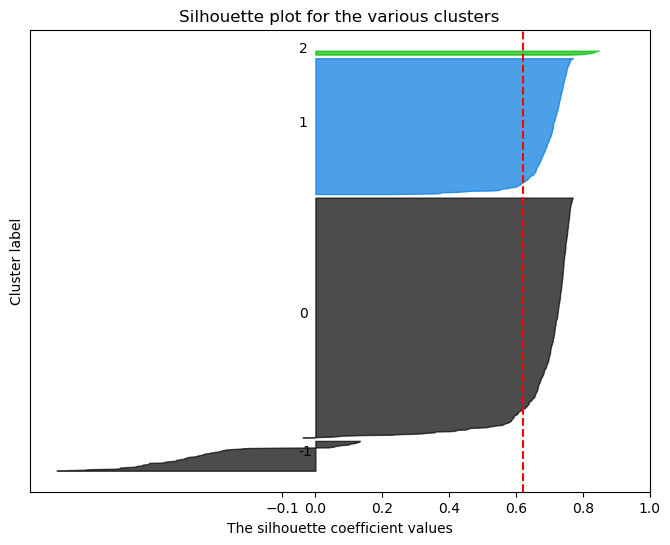

eps value is 6.7 min_samples is 14
{0, 1, -1}
For eps value = 6.7 The average silhouette_score is :0.6302738325681988
The average silhouette_score is : 0.6302738325681988


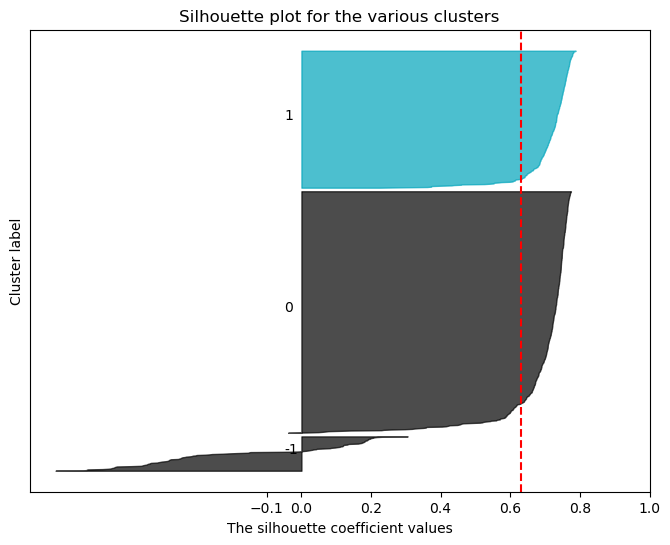

In [125]:
from sklearn.cluster import DBSCAN

X_bluebert = feature_matrix_bluebert.drop(columns=['NCT ID'])

# PCA
pca_bluebert = PCA(n_components=256)
X_pca_bluebert = pca_bluebert.fit_transform(X_bluebert)

range_eps= np.arange(6.3,7.2,0.2)
min_samples = np.arange(11,21,1)
max_silhouette_avg = 0
best_eps = 0
best_min_samples = 0
for i in range_eps:
    for j in min_samples:
        print("eps value is "+str(i)+" min_samples is "+str(j))
        db=DBSCAN(eps=i,min_samples=j).fit(X_pca_bluebert)
        core_samples_mask=np.zeros_like(db.labels_,dtype=bool)
        core_samples_mask[db.core_sample_indices_]=True
        labels=db.labels_
        print(set(labels))
        silhouette_avg=silhouette_score(X_pca_bluebert,labels)

        if silhouette_avg > max_silhouette_avg:
            max_silhouette_avg = silhouette_avg
            best_eps = i
            best_min_samples = j
            
        print("For eps value = "+str(i)+" The average silhouette_score is :"+str(silhouette_avg))
        plot_silhouette_samples(X_pca_bluebert, labels)

print(f"Best eps: {best_eps}")
print(f"Best min_samples: {best_min_samples}")
print(f"Best silhouette score: {max_silhouette_avg}")